# Operación Práctica de una Red Neuronal

In [4]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Reproducibilidad de los experimentos
torch.manual_seed(42)
np.random.seed(42)

### 1. Generación del conjunto de entrenamiento

In [5]:
# Se muestrea f(x) = sin(x) en [-2*pi, 2*pi] con m = 200 puntos.
# X y Y se organizan como matrices fila para vectorizar las
# operaciones sobre todas las muestras simultáneamente.
m = 200
x = torch.linspace(-2*np.pi, 2*np.pi, steps=m).reshape(1, m)
y = torch.sin(x)
X, Y = x, y  # X, Y en R^{1 x m}

### 2. Inicialización manual de W^(k) y b^(k)

In [6]:
n1, n2 = 32, 32  # Neuronas por capa oculta
W1 = torch.randn(n1, 1)  * np.sqrt(1.0/1)
b1 = torch.zeros(n1, 1)
W2 = torch.randn(n2, n1) * np.sqrt(1.0/n1)
b2 = torch.zeros(n2, 1)
W3 = torch.randn(1, n2)  * np.sqrt(1.0/n2)
b3 = torch.zeros(1, 1)

### 3. Hiperparámetros del entrenamiento

In [7]:
eta = 0.03 # Tasa de aprendizaje
n_epocas = 20000
historial_perdida = []

### 4. Ciclo de entrenamiento manual

In [8]:
for epoca in range(n_epocas):

    # ----- Evaluación directa (forward propagation) -----
    Z1 = W1 @ X + b1
    S1 = torch.tanh(Z1)
    Z2 = W2 @ S1 + b2
    S2 = torch.tanh(Z2)
    Z3 = W3 @ S2 + b3
    Y_hat = Z3

    # ----- Pérdida MSE -----
    L = ((Y_hat - Y)**2).mean()
    historial_perdida.append(L.item())

    # ----- Retropropagación manual -----
    # Capa de salida
    dZ3 = (2.0/m) * (Y_hat - Y)
    dW3 = dZ3 @ S2.T
    db3 = dZ3.sum(dim=1, keepdim=True)

    # Segunda capa oculta:
    dS2 = W3.T @ dZ3
    dZ2 = dS2 * (1 - S2**2)
    dW2 = dZ2 @ S1.T
    db2 = dZ2.sum(dim=1, keepdim=True)

    # Primera capa oculta:
    dS1 = W2.T @ dZ2
    dZ1 = dS1 * (1 - S1**2)
    dW1 = dZ1 @ X.T
    db1 = dZ1.sum(dim=1, keepdim=True)

    # ----- Actualización de los parámetros -----
    W1 -= eta * dW1;  b1 -= eta * db1
    W2 -= eta * dW2;  b2 -= eta * db2
    W3 -= eta * dW3;  b3 -= eta * db3

    if (epoca + 1) % 2000 == 0:
        print(f"Época {epoca+1:5d}/{n_epocas} | "
              f"Pérdida MSE: {L.item():.6e}")

Época  2000/20000 | Pérdida MSE: 5.758760e-02
Época  4000/20000 | Pérdida MSE: 3.578959e-02
Época  6000/20000 | Pérdida MSE: 2.113717e-02
Época  8000/20000 | Pérdida MSE: 1.099062e-02
Época 10000/20000 | Pérdida MSE: 6.611683e-03
Época 12000/20000 | Pérdida MSE: 4.932718e-03
Época 14000/20000 | Pérdida MSE: 4.537615e-03
Época 16000/20000 | Pérdida MSE: 3.927770e-03
Época 18000/20000 | Pérdida MSE: 3.545375e-03
Época 20000/20000 | Pérdida MSE: 2.643831e-03


### 5. Predicción final con la red entrenada

In [9]:
Z1 = W1 @ X + b1;  S1 = torch.tanh(Z1)
Z2 = W2 @ S1 + b2; S2 = torch.tanh(Z2)
Y_pred = (W3 @ S2 + b3).numpy()

### 6. Gráfica 1: aproximación vs función analítica

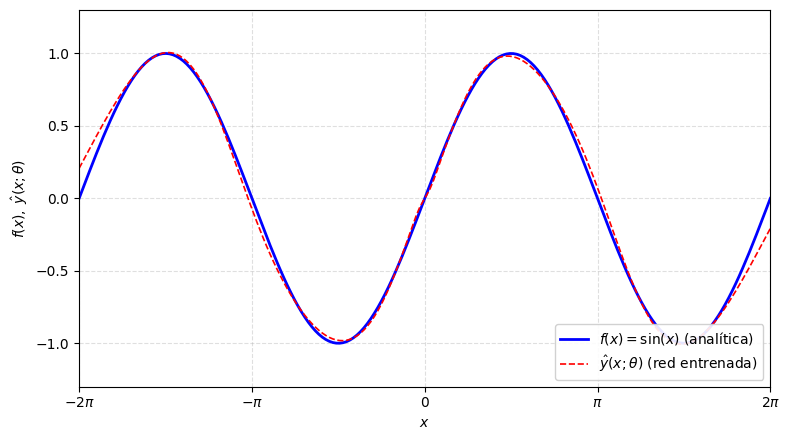

In [10]:
x_np   = X.numpy().flatten()
y_np   = Y.numpy().flatten()
y_pred = Y_pred.flatten()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x_np, y_np,
        color='blue', linewidth=2.0,
        label=r'$f(x) = \sin(x)$ (analítica)')
ax.plot(x_np, y_pred,
        color='red',  linewidth=1.2, linestyle='--',
        label=r'$\hat{y}(x;\theta)$ (red entrenada)')
ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$f(x), \; \hat{y}(x;\theta)$')
ax.set_xlim(-2*np.pi, 2*np.pi)
ax.set_ylim(-1.3, 1.3)
ax.set_xticks([-2*np.pi, -np.pi, 0, np.pi, 2*np.pi])
ax.set_xticklabels([r'$-2\pi$', r'$-\pi$', r'$0$', r'$\pi$', r'$2\pi$'])
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='lower right', framealpha=0.9)
fig.tight_layout()
plt.show()
plt.close(fig)

### 7. Gráfica 2: curva de decaimiento de la pérdida

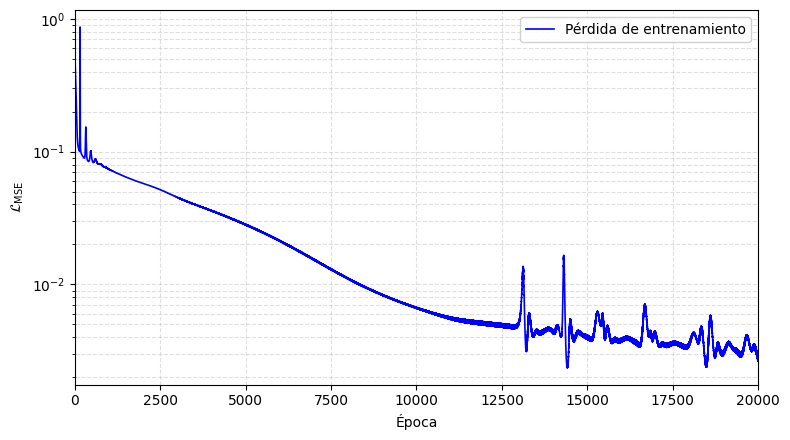

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(range(1, n_epocas + 1), historial_perdida,
            color='blue', linewidth=1.2,
            label='Pérdida de entrenamiento')
ax.set_xlabel('Época')
ax.set_ylabel(r'$\mathcal{L}_{\mathrm{MSE}}$')
ax.set_xlim(0, n_epocas)
ax.grid(True, which='both', linestyle='--', alpha=0.4)
ax.legend(loc='upper right', framealpha=0.9)
fig.tight_layout()
plt.show()
plt.close(fig)

### 8. Métrica final: error máximo absoluto

In [12]:
error_max = np.max(np.abs(y_np - y_pred))
error_l2  = np.sqrt(np.mean((y_np - y_pred)**2))
print(f"Error máximo |y - y_hat|: {error_max:.6e}")
print(f"Error RMSE sobre el conjunto: {error_l2:.6e}")

Error máximo |y - y_hat|: 2.075303e-01
Error RMSE sobre el conjunto: 5.281889e-02
